# RevenueVision – Sales Analytics and Forecasting Platform

## Project Introduction

RevenueVision is a data analytics and machine learning project developed to analyse sales data and forecast future sales.

The main objective of this project is to understand sales performance, identify business trends, analyse customer purchasing behaviour, and predict future sales using machine learning techniques.

This project uses the Superstore Sales Dataset obtained from Kaggle. It includes data preprocessing, exploratory data analysis (EDA), feature engineering, SQL analysis, customer segmentation, and machine learning model development.

The project aims to provide useful business insights and support better decision-making through data analysis and forecasting.

## Tools and Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SQL (SQLite)
- Scikit-learn
- XGBoost
- Gradio

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
df=pd.read_csv('/content/drive/MyDrive/Data/Superstore.csv',encoding='latin1')
df


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2011-110422,22-01-2011,24-01-2011,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [ ]:
#Understanding the dataset
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.shape


(9994, 21)

In [ ]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
#checking missing values
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [ ]:
#Checking duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,11-10-2012,18-10-2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2011-110422,22-01-2011,24-01-2011,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2014-121258,27-02-2014,04-03-2014,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [ ]:
#Converting date Columns
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

In [ ]:
#Feature Engineering
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Day'] = df['Order Date'].dt.day
df['month_name'] = df['Order Date'].dt.month_name()

In [ ]:
#Final preprocessing check
print('Dataset shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Dataset shape: (9994, 25)
Missing values: 0
Duplicate rows: 0


**EDA**

In [ ]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2013-04-30 19:20:02.401441024,2013-05-04 18:20:49.229537792,55190.379428,229.858001,3.789574,0.156203,28.656896,2012.722934,7.814589,15.647889
min,1.000000,2011-01-04 00:00:00,2011-01-08 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2011.000000,1.000000,1.000000
25%,2499.250000,2012-05-23 00:00:00,2012-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2012.000000,5.000000,8.000000
50%,4997.500000,2013-06-27 00:00:00,2013-06-30 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2013.000000,9.000000,16.000000
75%,7495.750000,2014-05-15 00:00:00,2014-05-19 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2014.000000,11.000000,23.000000
max,9994.000000,2014-12-31 00:00:00,2015-01-06 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2014.000000,12.000000,31.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.124039,3.286047,8.731091


In [ ]:
#Overall business performance
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_quantity = df['Quantity'].sum()
total_orders = df['Order ID'].nunique()

print('Total_sales:',total_sales)
print('Total_profit:',total_profit)
print('Total_quantity:',total_quantity)
print('Total_orders:',total_orders)

Total_sales: 2297200.8603
Total_profit: 286397.0217
Total_quantity: 37873
Total_orders: 5009


In [ ]:
#Sales Analysis by product category

category_sales = df.groupby('Category')['Sales'].sum()
category_sales

,Sales
Category,
Furniture,741999.7953
Office Supplies,719047.0320
Technology,836154.0330


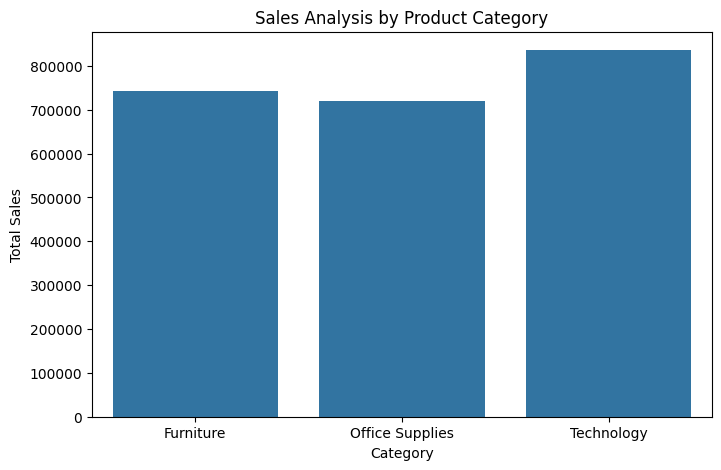

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.title('Sales Analysis by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
#Sales analysis by region

region_sales = df.groupby('Region')['Sales'].sum()
region_sales

,Sales
Region,
Central,501239.8908
East,678781.2400
South,391721.9050
West,725457.8245


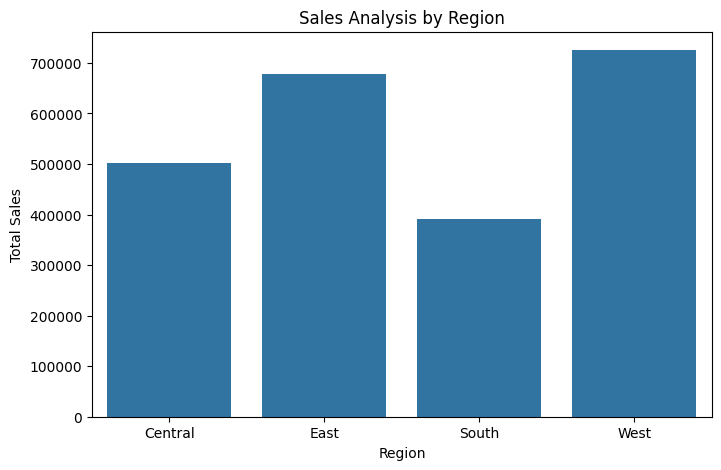

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title('Sales Analysis by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
#Profit analysis by product category
category_profit = df.groupby('Category')['Profit'].sum()
category_profit

,Profit
Category,
Furniture,18451.2728
Office Supplies,122490.8008
Technology,145454.9481


<function matplotlib.pyplot.show(close=None, block=None)>

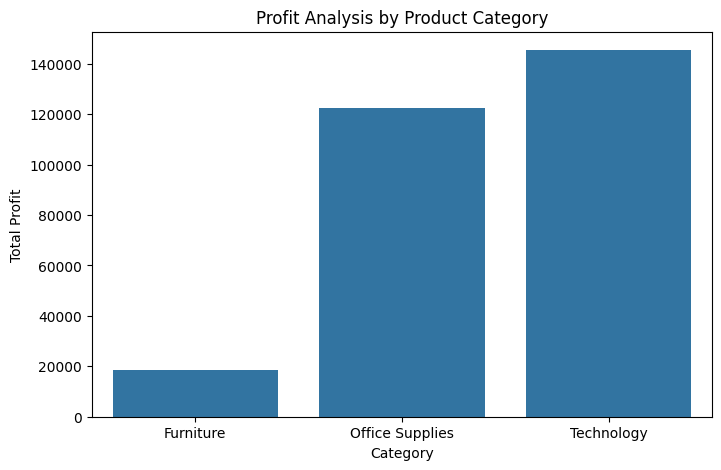

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=category_profit.index, y=category_profit.values)
plt.title('Profit Analysis by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.show

In [ ]:
#sub-category analysis
sub_category_sales = df.groupby('Sub-Category')['Profit'].sum()
print(sub_category_sales.sort_values(ascending=False))

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


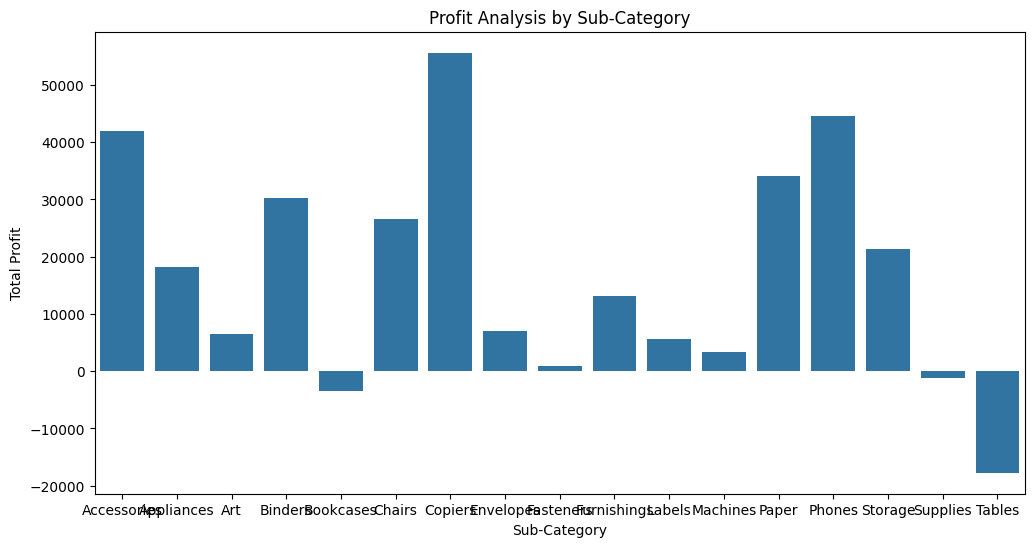

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=sub_category_sales.index, y=sub_category_sales.values)
plt.title('Profit Analysis by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit')
plt.show()

In [ ]:
#Monthly sales trend
monthly_sales = df.groupby('Order Month')['Sales'].sum()
monthly_sales

,Sales
Order Month,
1,95365.9376
2,60172.6494
3,199252.9840
4,141851.5674
5,156122.2867
6,147082.6113
7,149580.8380
8,159589.4510
9,309770.0997


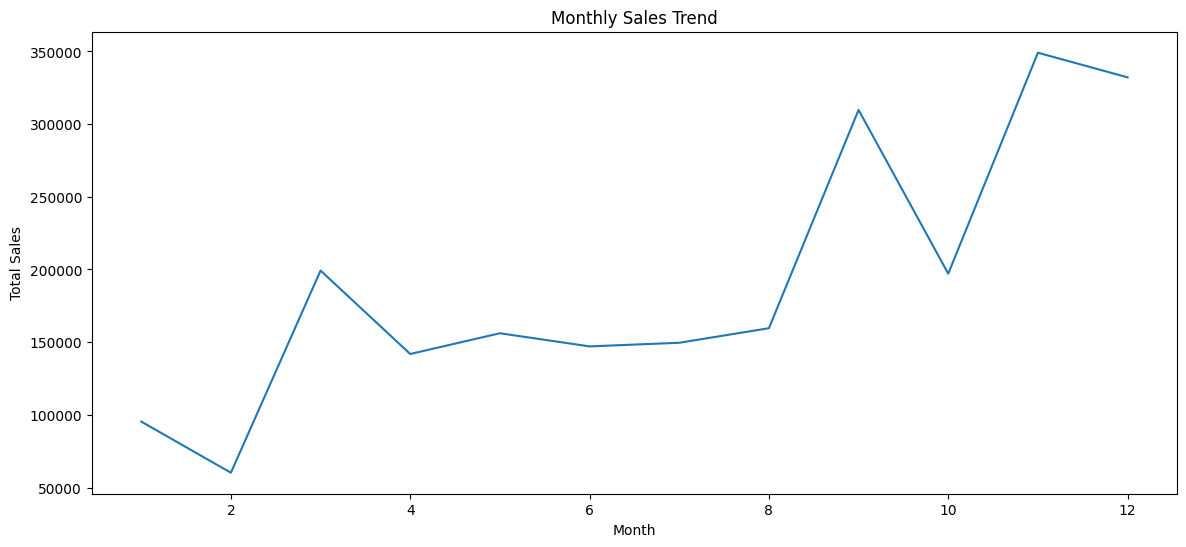

In [ ]:
plt.figure(figsize=(14,6))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values)
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

In [ ]:
#Customer Segment Analysis

segment_sales = df.groupby('Segment')['Sales'].sum()
segment_sales

,Sales
Segment,
Consumer,1.161401e+06
Corporate,7.061464e+05
Home Office,4.296531e+05


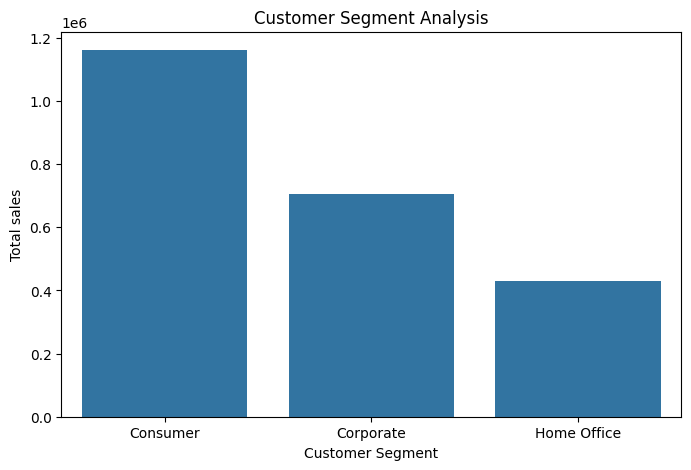

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)
plt.title("Customer Segment Analysis")
plt.xlabel('Customer Segment')
plt.ylabel('Total sales')
plt.show()

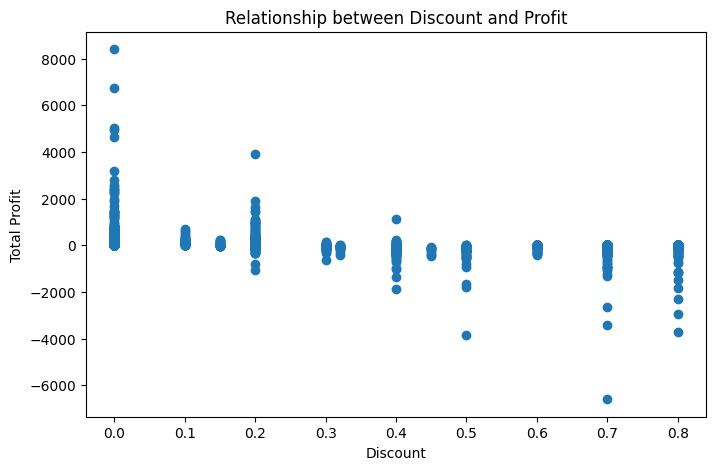

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['Discount'],df['Profit'])
plt.title('Relationship between Discount and Profit')
plt.xlabel('Discount')
plt.ylabel('Total Profit')
plt.show()

In [ ]:
#Correlation analysis
correlation = df[['Sales','Quantity','Discount','Profit']].corr()
correlation

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


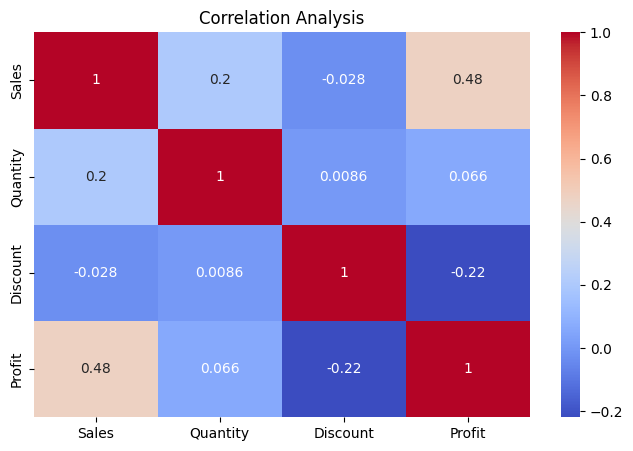

In [ ]:
plt.figure(figsize=(8,5))
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.title('Correlation Analysis')
plt.show()

SQL Analysis

In [45]:
import sqlite3

conn = sqlite3.connect('superstore.db')

df.to_sql('superstore', conn, if_exists='replace', index=False)

print("Database created successfully!")

Database created successfully!


In [46]:
#total sales
query = """
SELECT SUM(Sales) AS Total_Sales
FROM superstore;
"""

result = pd.read_sql_query(query, conn)
print(result)

    Total_Sales
0  2.297201e+06


In [47]:
#sales by category
query = """
SELECT Category, SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY Category;
"""

result = pd.read_sql_query(query, conn)
print(result)

          Category  Total_Sales
0        Furniture  741999.7953
1  Office Supplies  719047.0320
2       Technology  836154.0330


In [48]:
#sales by region
query = """
SELECT Region, SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY Region;
"""

result = pd.read_sql_query(query, conn)
print(result)

    Region  Total_Sales
0  Central  501239.8908
1     East  678781.2400
2    South  391721.9050
3     West  725457.8245


In [50]:
#Top products
query = """
SELECT "Product Name", SUM(Sales) AS Total_Sales
FROM superstore
GROUP BY "Product Name"
ORDER BY Total_Sales DESC
LIMIT 5;
"""
result= pd.read_sql_query(query, conn)
print(result)

                                        Product Name  Total_Sales
0              Canon imageCLASS 2200 Advanced Copier    61599.824
1  Fellowes PB500 Electric Punch Plastic Comb Bin...    27453.384
2  Cisco TelePresence System EX90 Videoconferenci...    22638.480
3       HON 5400 Series Task Chairs for Big and Tall    21870.576
4         GBC DocuBind TL300 Electric Binding System    19823.479


Customer Segmentation by clustering

In [51]:
customer_data = df.groupby('Customer ID').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum',
    'Order ID': 'nunique'
}).reset_index()

customer_data.columns = [
    'Customer_ID',
    'Total_Sales',
    'Total_Profit',
    'Total_Quantity',
    'Total_Orders'
]

print(customer_data.head())

  Customer_ID  Total_Sales  Total_Profit  Total_Quantity  Total_Orders
0    AA-10315     5563.560     -362.8825              30             5
1    AA-10375     1056.390      277.3824              41             9
2    AA-10480     1790.512      435.8274              36             4
3    AA-10645     5086.935      857.8033              64             6
4    AB-10015      886.156      129.3465              13             3


In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = customer_data[
    ['Total_Sales', 'Total_Profit',
     'Total_Quantity', 'Total_Orders']
]

scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

customer_data['Customer_Cluster'] = kmeans.fit_predict(scaled_data)

print(customer_data.head())

  Customer_ID  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0    AA-10315     5563.560     -362.8825              30             5   
1    AA-10375     1056.390      277.3824              41             9   
2    AA-10480     1790.512      435.8274              36             4   
3    AA-10645     5086.935      857.8033              64             6   
4    AB-10015      886.156      129.3465              13             3   

   Customer_Cluster  
0                 2  
1                 1  
2                 2  
3                 1  
4                 2  


In [53]:
cluster_summary = customer_data.groupby('Customer_Cluster')[
    ['Total_Sales', 'Total_Profit',
     'Total_Quantity', 'Total_Orders']
].mean()

print(cluster_summary)

                  Total_Sales  Total_Profit  Total_Quantity  Total_Orders
Customer_Cluster                                                         
0                 9182.107395   2133.640149       77.349206      8.396825
1                 3413.264137    307.317271       64.768254      8.314286
2                 1550.722630    132.946390       30.356627      4.484337


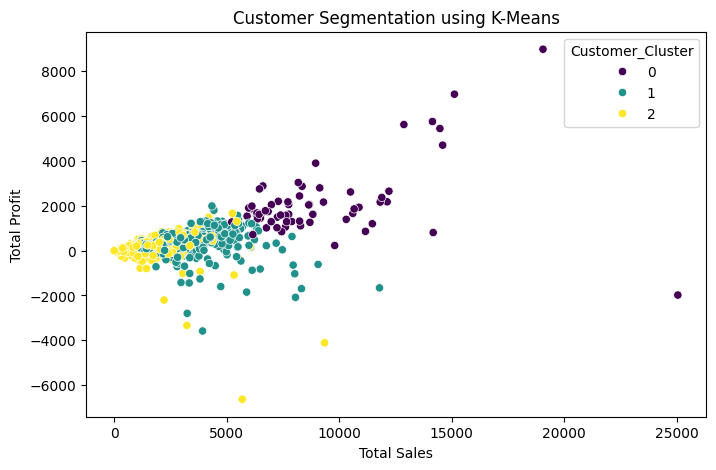

In [54]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=customer_data,
    x='Total_Sales',
    y='Total_Profit',
    hue='Customer_Cluster',
    palette='viridis'
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Total Sales')
plt.ylabel('Total Profit')
plt.show()

**Model Building and Training**

In [ ]:
#prepare dataset for forecasting
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
monthly_df = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum().reset_index()
monthly_df.columns = ['Month' , 'Sales']
monthly_df['Month'] = monthly_df['Month'].dt.to_timestamp()
monthly_df.head()

,Month,Sales
0,2011-01-01,19462.193
1,2011-02-01,12090.872
2,2011-03-01,7257.756
3,2011-04-01,12146.598
4,2011-05-01,15683.319


In [ ]:
monthly_df['Year'] = monthly_df['Month'].dt.year
monthly_df['Month'] = monthly_df['Month'].dt.month
monthly_df['Lag_1'] = monthly_df['Sales'].shift(1)
monthly_df['Lag_2'] = monthly_df['Sales'].shift(2)
monthly_df['Lag_3'] = monthly_df['Sales'].shift(3)
monthly_df['Rolling_mean'] = (
    monthly_df['Sales']
    .rolling(window=3)
    .mean().shift(1)
)
monthly_df.head(10)

,Month,Sales,Year,Lag_1,Lag_2,Lag_3,Rolling_mean
0,1,19462.193,2011,NaN,NaN,NaN,NaN
1,2,12090.872,2011,19462.193,NaN,NaN,NaN
2,3,7257.756,2011,12090.872,19462.193,NaN,NaN
3,4,12146.598,2011,7257.756,12090.872,19462.193,12936.940333
4,5,15683.319,2011,12146.598,7257.756,12090.872,10498.408667
5,6,7209.773,2011,15683.319,12146.598,7257.756,11695.891000
6,7,14692.562,2011,7209.773,15683.319,12146.598,11679.896667
7,8,27050.681,2011,14692.562,7209.773,15683.319,12528.551333
8,9,17132.948,2011,27050.681,14692.562,7209.773,16317.672000
9,10,10098.355,2011,17132.948,27050.681,14692.562,19625.397000


In [ ]:
monthly_df = monthly_df.dropna()
monthly_df = monthly_df.reset_index(drop=True)
monthly_df.head()

,Month,Sales,Year,Lag_1,Lag_2,Lag_3,Rolling_mean
0,4,12146.598,2011,7257.756,12090.872,19462.193,12936.940333
1,5,15683.319,2011,12146.598,7257.756,12090.872,10498.408667
2,6,7209.773,2011,15683.319,12146.598,7257.756,11695.891000
3,7,14692.562,2011,7209.773,15683.319,12146.598,11679.896667
4,8,27050.681,2011,14692.562,7209.773,15683.319,12528.551333


In [ ]:
X = monthly_df[
    ['Month','Year','Lag_1','Lag_2','Lag_3','Rolling_mean']
]
y = monthly_df['Sales']


In [ ]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(36, 6)
(9, 6)
(36,)
(9,)


In [ ]:
#import machine learning algorithms

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [ ]:
#Linear Regression

lr_model = LinearRegression()
lr_model.fit(X_train,y_train)
lr_pred = lr_model.predict(X_test)

In [ ]:
#Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
     random_state=42
)
rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)

In [ ]:
#XGBoost

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
xgb_model.fit(X_train,y_train)
xgb_pred = xgb_model.predict(X_test)

In [ ]:
#predicted sales

res = pd.DataFrame({
    'Month': monthly_df['Month'].iloc[split:].values,
    'Actual Sales': y_test.values,
    'Linear Regression': lr_pred,
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred
})
res

,Month,Actual Sales,Linear Regression,Random Forest,XGBoost
0,4,26899.4730,29919.457564,27669.320310,25431.744141
1,5,21446.7670,24507.471533,25702.236830,24912.144531
2,6,15979.1570,25641.569854,21943.544606,18307.193359
3,7,12648.9558,23100.528506,19976.588202,19150.976562
4,8,25110.4795,22210.540179,20714.126545,20203.164062
5,9,26823.6900,27837.960090,21198.251167,17675.099609
6,10,23148.8700,23921.313193,22180.663842,16306.181641
7,11,17558.3220,23219.715823,22647.245685,17025.048828
8,12,18206.2000,21777.688678,20689.817296,17140.556641


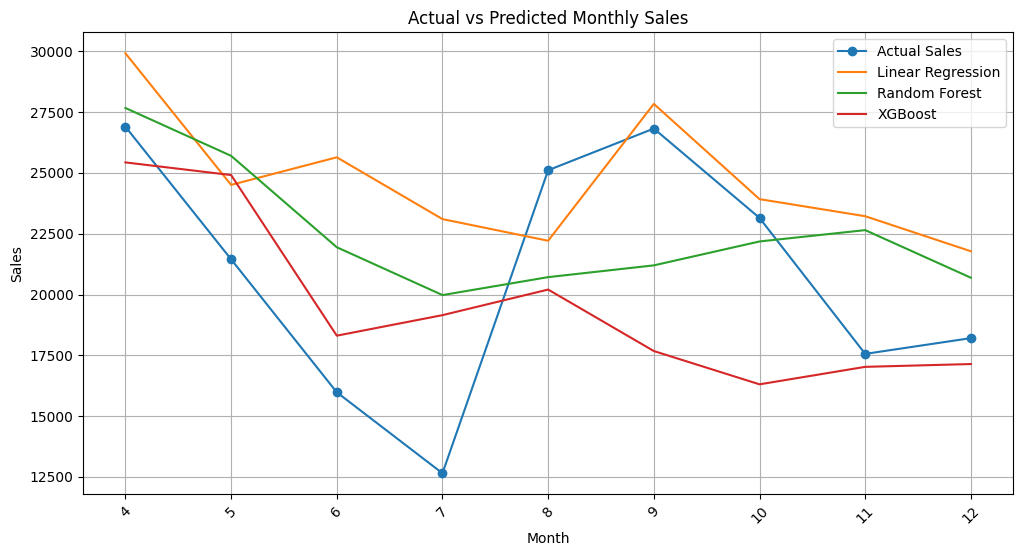

In [34]:
plt.figure(figsize=(12,6))

plt.plot(
    res['Month'],
    res['Actual Sales'],
    label='Actual Sales',
    marker='o'
)

plt.plot(
    res['Month'],
    res['Linear Regression'],
    label='Linear Regression'
)

plt.plot(
    res['Month'],
    res['Random Forest'],
    label='Random Forest'
)

plt.plot(
    res['Month'],
    res['XGBoost'],
    label='XGBoost'
)

plt.title('Actual vs Predicted Monthly Sales')

plt.xlabel('Month')
plt.ylabel('Sales')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

**Model Evaluation**

In [36]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [37]:
models = {
    'Linear Regression': lr_pred,
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred
}

evaluation_results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    evaluation_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df)

               Model          MAE           MSE         RMSE  R2 Score
0  Linear Regression  4457.134418  3.065864e+07  5537.024722 -0.346794
1      Random Forest  4097.764008  2.132736e+07  4618.155093  0.063117
2            XGBoost  4028.963803  2.420888e+07  4920.251887 -0.063464


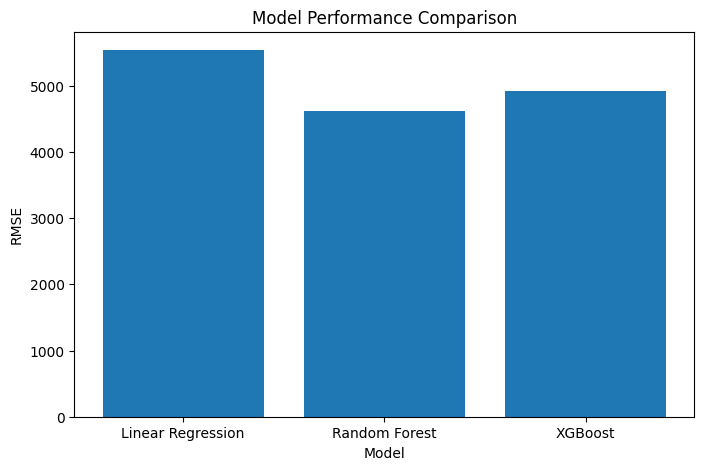

In [38]:
plt.figure(figsize=(8,5))
plt.bar(evaluation_df['Model'], evaluation_df['RMSE'])
plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.show()

In [55]:
#Save the best model
import joblib

model_dictionary = {
    'Linear Regression': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

best_model_name = evaluation_df.loc[
    evaluation_df['RMSE'].idxmin(), 'Model'
]

best_model = model_dictionary[best_model_name]

joblib.dump(best_model, 'best_sales_model.joblib')

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: Random Forest
Model saved successfully!


**UI Integration**

In [42]:
import gradio as gr

In [43]:
#create the prediction function

def predict_sales(model_name, year, month, lag1, lag2, lag3):

    rolling_mean = np.mean([lag1, lag2, lag3])

    input_data = pd.DataFrame({
        'Year': [int(year)],
        'Month_Number': [int(month)],
        'Lag_1': [lag1],
        'Lag_2': [lag2],
        'Lag_3': [lag3],
        'Rolling_Mean': [rolling_mean]
    })

    models = {
        'Linear Regression': lr_model,
        'Random Forest': rf_model,
        'XGBoost': xgb_model
    }

    selected_model = models[model_name]

    prediction = selected_model.predict(input_data)[0]

    return f"Predicted Sales: {prediction:,.2f}"

In [44]:
app = gr.Interface(
    fn=predict_sales,

    inputs=[
        gr.Dropdown(
            choices=[
                'Linear Regression',
                'Random Forest',
                'XGBoost'
            ],
            label='Select Model'
        ),

        gr.Number(label='Year', value=2015),
        gr.Number(label='Month (1-12)', value=1),

        gr.Number(label='Previous Month Sales', value=20000),
        gr.Number(label='Sales Two Months Ago', value=18000),
        gr.Number(label='Sales Three Months Ago', value=22000)
    ],

    outputs=gr.Textbox(label='Sales Prediction'),

    title='RevenueVision – Sales Analytics & Forecasting Platform',

    description='Predict monthly sales using Machine Learning models.'
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aab08f2ca92537113e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Conclusion

The RevenueVision project successfully demonstrates the use of data analytics and machine learning techniques for sales analysis and forecasting.

The Superstore dataset was processed and analysed to identify important sales trends, profitable categories, regional performance, and customer purchasing patterns.

SQL analysis was performed to extract useful business insights, and K-Means clustering was used for customer segmentation. Different machine learning models were developed to predict future sales.

This project provided practical experience in data preprocessing, data visualization, SQL queries, customer segmentation, and machine learning.

Overall, RevenueVision demonstrates how data-driven insights can help businesses understand their performance and make better decisions.